# Project Title:
### PRCP- 1001- RiceLeaf disease detection

# Objective

- To analyze the rice leaf disease image dataset
- To build image classification models for disease detection
- To compare multiple models and select the best performing model
- To study the impact of data augmentation on model performance


# Import Libraries

In [1]:
import os
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
%matplotlib inline
import tensorflow as tf
import warnings 
warnings.filterwarnings('ignore')
from PIL import Image

from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,MaxPooling2D,Flatten,Dense,Dropout
from tensorflow.keras.callbacks import EarlyStopping


C:\Users\Hp EliteBook\AppData\Roaming\Python\Python312\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


# Load Data

In [2]:
os.getcwd()

'C:\\Users\\Hp EliteBook\\internship Projects\\PRCP-1001-RiceLeaf'

In [3]:
dataset_path = "C:\\Users\\Hp EliteBook\\internship Projects\\PRCP-1001-RiceLeaf/Data" 

classes = [
    cls for cls in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, cls)) and not cls.startswith(".")
]
print("Classes:", classes)


Classes: ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']


# Basic checks

In [4]:
image_count = {}

for cls in classes:
    class_path = os.path.join(dataset_path, cls)
    image_count[cls] = len(os.listdir(class_path))

image_count

{'Bacterial leaf blight': 40, 'Brown spot': 40, 'Leaf smut': 39}

- The dataset contains three rice leaf disease classes.
- A slight variation in image count is observed across classes.
- The dataset is nearly balanced, which is suitable for training classification models.

In [5]:
img_paths = []
labels = []

for cls in classes:
    class_path = os.path.join(dataset_path, cls)
    for img_name in os.listdir(class_path):
        img_paths.append(os.path.join(class_path, img_name))
        labels.append(cls)

print("Total images:", len(img_paths))
print("Total labels:", len(labels))

Total images: 119
Total labels: 119


In [6]:
#The total number of image paths matches the number of labels.This confirms that all images are correctly mapped to their respective classes.

In [7]:
df = pd.DataFrame({
    "image_path": img_paths,
    "label": labels
})

df.head()

,image_path,label
0,C:\Users\Hp EliteBook\internship Projects\PRCP...,Bacterial leaf blight
1,C:\Users\Hp EliteBook\internship Projects\PRCP...,Bacterial leaf blight
2,C:\Users\Hp EliteBook\internship Projects\PRCP...,Bacterial leaf blight
3,C:\Users\Hp EliteBook\internship Projects\PRCP...,Bacterial leaf blight
4,C:\Users\Hp EliteBook\internship Projects\PRCP...,Bacterial leaf blight


# Domain Analysis

Rice is a major staple crop and plays a vital role in global food security.
However, rice plants are susceptible to several leaf diseases that can
significantly reduce crop yield and quality.

Leaf Smut is a fungal disease characterized by dark spots on leaves.
Brown Spot causes brown circular lesions, while Bacterial Leaf Blight
leads to yellowing and drying of leaf margins.

Early identification of these diseases using image-based classification
techniques can assist farmers in taking timely preventive measures and
minimizing crop losses.

# EDA

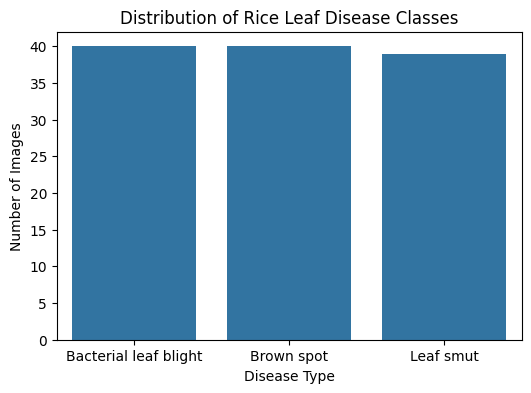

In [8]:
plt.figure(figsize=(6,4))
sns.countplot(x="label", data=df)
plt.title("Distribution of Rice Leaf Disease Classes")
plt.xlabel("Disease Type")
plt.ylabel("Number of Images")
plt.show()

In [9]:
#The bar chart shows a nearly balanced distribution of disease classes.

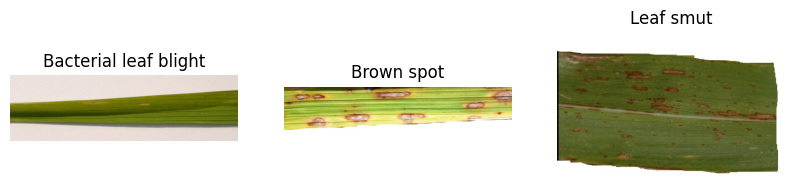

In [10]:
import random 
plt.figure(figsize=(10,4))

for i, cls in enumerate(classes):
    class_images = df[df["label"] == cls]["image_path"].values
    sample_image = random.choice(class_images)
    img = Image.open(sample_image)
    
    plt.subplot(1, 3, i+1)
    plt.imshow(img)
    plt.title(cls)
    plt.axis("off")

plt.show()

In [11]:
#Sample images reveal distinct visual characteristics for each disease type.

In [12]:
sizes = df["image_path"].apply(lambda x: Image.open(x).size)

sizes_df = pd.DataFrame(sizes.tolist(), columns=["Width", "Height"])
sizes_df.describe()

,Width,Height
count,119.000000,119.000000
mean,2383.638655,707.739496
std,1123.528972,311.657582
min,250.000000,71.000000
25%,1074.000000,377.000000
50%,3081.000000,897.000000
75%,3081.000000,897.000000
max,3081.000000,900.000000


In [13]:
#Image dimensions vary across the dataset.Resizing images to a fixed size will be required before model training.

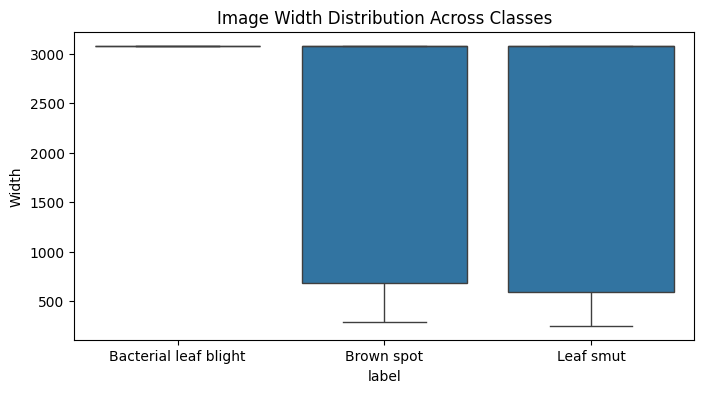

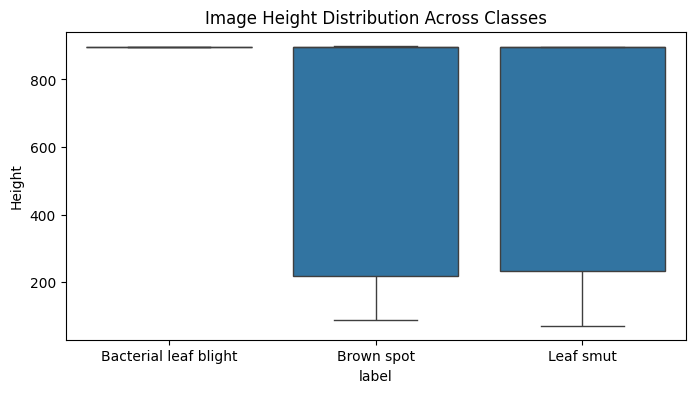

In [14]:
df=df.join(sizes_df)
plt.figure(figsize=(8,4))
sns.boxplot(x="label", y="Width", data=df)
plt.title("Image Width Distribution Across Classes")
plt.show()

plt.figure(figsize=(8,4))
sns.boxplot(x="label", y="Height", data=df)
plt.title("Image Height Distribution Across Classes")
plt.show()

In [15]:
#The width and height of images varies significantly across all disease classes.No single class shows a uniquely consistent width pattern.This variation indicates that images were captured under different conditions.

# Data Preprocessing

In [16]:
IMG_SIZE = (224, 224)   #A standard input size for CNN and transfer learning models.

In [17]:
def load_and_preprocess_images(image_paths, img_size):
    images = []
    
    for path in image_paths:
        img = Image.open(path).convert("RGB")
        img = img.resize(img_size)
        images.append(np.array(img))
        
    return np.array(images)

In [18]:
label_map = {label: idx for idx, label in enumerate(classes)}
y = np.array([label_map[label] for label in labels])

In [19]:
# Class labels were encoded into numerical format for model compatibility.

In [20]:
X = load_and_preprocess_images(img_paths, IMG_SIZE)

print("Feature shape:", X.shape)
print("Label shape:", y.shape)


Feature shape: (119, 224, 224, 3)
Label shape: (119,)


In [21]:
X = X / 255.0

In [22]:
# Pixel values were normalized to the range [0, 1] to improve training stability.

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [24]:
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 95
Testing samples: 24


# CNN Model Building

In [25]:
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)),
    MaxPooling2D(2,2),
    
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    
    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(len(classes), activation='softmax')
])


In [26]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [27]:
#Adam optimizer provides fast and stable convergence.
#Sparse categorical crossentropy is suitable for integer-encoded labels.
#Accuracy is used as the primary evaluation metric.

In [28]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 86528)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      11,075,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,169,347 (42.61 MB)

 Trainable params: 11,169,347 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [29]:
#The model consists of convolutional layers for feature extraction and dense layers for classification.

In [30]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=20,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.2895 - loss: 3.9214 - val_accuracy: 0.3684 - val_loss: 1.1904
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.2368 - loss: 1.5212 - val_accuracy: 0.3684 - val_loss: 1.0896
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.3816 - loss: 1.0830 - val_accuracy: 0.2105 - val_loss: 1.0934
Epoch 4/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.4868 - loss: 1.0578 - val_accuracy: 0.2105 - val_loss: 1.2519
Epoch 5/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.3947 - loss: 1.1237 - val_accuracy: 0.5263 - val_loss: 0.9622
Epoch 6/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.5789 - loss: 0.9716 - val_accuracy: 0.3684 - val_loss: 1.1290
Epoch 7/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.5263 - loss: 0.9800 - val_accuracy: 0.6316 - val_loss: 0.8737
Epoch 8/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.6316 - loss: 0.8360 - val_accuracy: 0.5789 - val_loss: 0.8273
Epoch 9/20
3/3 

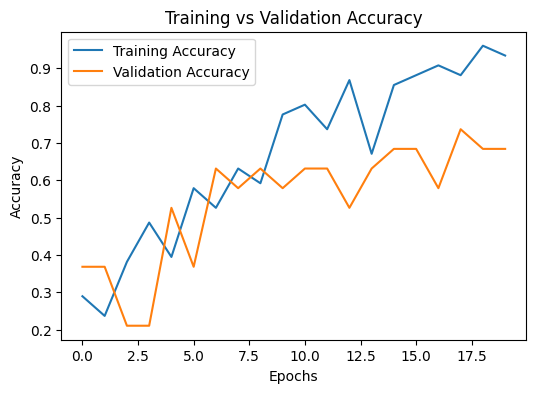

In [31]:
plt.figure(figsize=(6,4))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.show()


In [32]:
# The training accuracy shows continuous improvement, while validation accuracy stabilizes after a certain point. 
# This divergence indicates that the model is overfitting and learning training-specific patterns rather than general features.

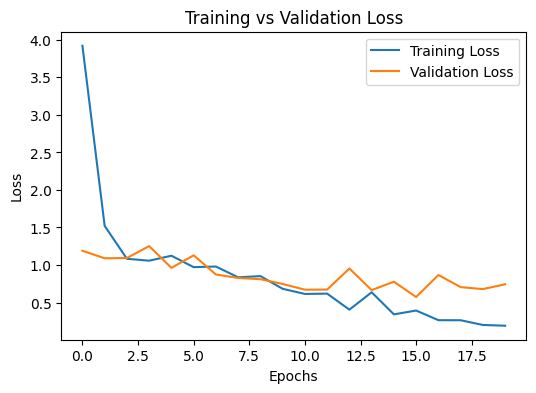

In [33]:
plt.figure(figsize=(6,4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()


In [34]:
# While training loss consistently decreases, validation loss shows fluctuations after several epochs. 
# This behavior further confirms overfitting, suggesting that the model’s ability to generalize does not improve beyond a certain training point.


In [35]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Test Accuracy:", test_accuracy)


Test Accuracy: 0.75


In [36]:
#The model performs reasonably well on unseen data, correctly identifying most rice leaf diseases. However, its performance can be further improved by using advanced training techniques to enhance generalization.

# Model Evaluation

In [37]:
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 523ms/step


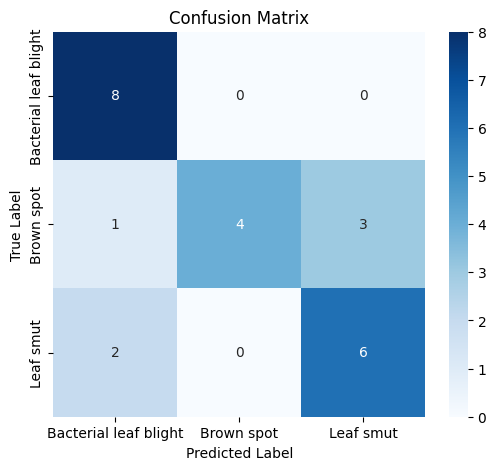

In [38]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes,
            yticklabels=classes)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()


In [39]:
#The confusion matrix shows perfect classification for Bacterial leaf blight, while Brown spot has the highest misclassification rate due to visual similarity with Leaf smut.
#Overall, the results align with the observed test accuracy of 75%.

In [40]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=classes))


                       precision    recall  f1-score   support

Bacterial leaf blight       0.73      1.00      0.84         8
           Brown spot       1.00      0.50      0.67         8
            Leaf smut       0.67      0.75      0.71         8

             accuracy                           0.75        24
            macro avg       0.80      0.75      0.74        24
         weighted avg       0.80      0.75      0.74        24



In [41]:
#The classification report highlights strong performance for Bacterial leaf blight, while Brown spot remains the most challenging class due to lower recall. 
#Overall,the model achieves balanced precision and recall across classes, with an accuracy of 75%. 
#These results validate the baseline CNN while highlighting opportunities for improvement through advanced modeling techniques.

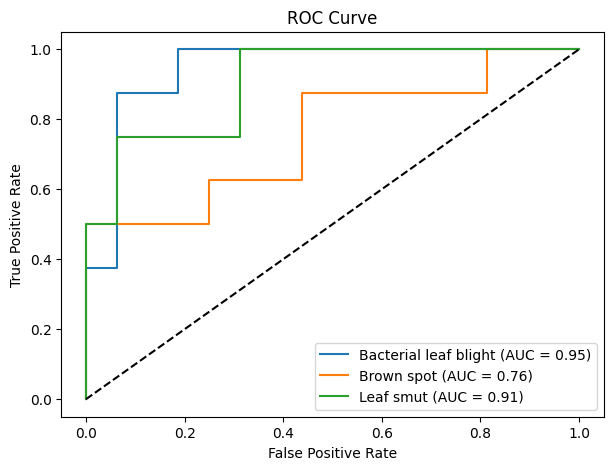

In [42]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

y_test_bin = label_binarize(y_test, classes=range(len(classes)))

plt.figure(figsize=(7,5))
for i in range(len(classes)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_probs[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{classes[i]} (AUC = {roc_auc:.2f})")

plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


In [43]:
#The ROC curves indicate that the model has strong discriminative power acrossclasses, particularly for Bacterial leaf blight and Leaf smut.
#The comparatively lower AUC for Brown spot aligns with previous evaluation metrics and highlights the need for further feature enhancement.


In [44]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Final Test Accuracy: {test_accuracy:.4f}")


Final Test Accuracy: 0.7500


# Data Augmentation

In [70]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True
)


In [73]:
#To improve model generalization and reduce overfitting caused by the limited dataset size, data augmentation is applied to the training images.

In [71]:
aug_history = improved_model.fit(
    datagen.flow(X_train, y_train, batch_size=16),
    epochs=25,
    validation_data=(X_test, y_test),
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.8211 - loss: 0.5221 - val_accuracy: 0.3333 - val_loss: 1.1091
Epoch 2/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.8105 - loss: 0.4843 - val_accuracy: 0.3333 - val_loss: 1.1140
Epoch 3/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.8316 - loss: 0.5141 - val_accuracy: 0.3333 - val_loss: 1.1192
Epoch 4/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.8105 - loss: 0.5261 - val_accuracy: 0.3333 - val_loss: 1.1259
Epoch 5/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.8526 - loss: 0.4512 - val_accuracy: 0.3333 - val_loss: 1.1319
Epoch 6/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.8000 - loss: 0.5297 - val_accuracy: 0.3333 - val_loss: 1.1363
Epoch 7/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.7895 - loss: 0.5262 - val_accuracy: 0.3333 - val_loss: 1.1414
Epoch 8/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 1000ms/step - accuracy: 0.8316 - loss: 0.4954 - val_accuracy: 0.3333 - val_loss: 1.1439
Epoch 8: ear

In [72]:
test_loss, test_accuracy = improved_model.evaluate(X_test, y_test, verbose=0)

print("Test Accuracy:", test_accuracy)


Test Accuracy: 0.3333333432674408


In [74]:
#The model learned well on training data but failed to perform on unseen images.
#Data augmentation increased complexity without adding useful information due to the small dataset size, leading to poor generalization.

# Tranfer learning model

In [48]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.models import Model

base_model = MobileNetV2(
    input_shape=(224,224,3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False


In [49]:
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
output = Dense(len(classes), activation='softmax')(x)

tl_model = Model(inputs=base_model.input, outputs=output)


In [50]:
tl_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [51]:
tl_history = tl_model.fit(
    X_train, y_train,
    epochs=15,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 21s 3s/step - accuracy: 0.3684 - loss: 1.7425 - val_accuracy: 0.5789 - val_loss: 1.0242
Epoch 2/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 868ms/step - accuracy: 0.6579 - loss: 0.7569 - val_accuracy: 0.7895 - val_loss: 0.6018
Epoch 3/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step - accuracy: 0.7763 - loss: 0.5166 - val_accuracy: 0.8421 - val_loss: 0.5429
Epoch 4/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 876ms/step - accuracy: 0.8947 - loss: 0.2861 - val_accuracy: 0.7895 - val_loss: 0.5496
Epoch 5/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 863ms/step - accuracy: 0.8947 - loss: 0.3237 - val_accuracy: 0.7368 - val_loss: 0.5702
Epoch 6/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 918ms/step - accuracy: 0.8684 - loss: 0.3042 - val_accuracy: 0.7895 - val_loss: 0.4884
Epoch 7/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 911ms/step - accuracy: 0.9737 - loss: 0.2067 - val_accuracy: 0.8421 - val_loss: 0.4317
Epoch 8/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 925ms/step - accuracy: 0.9342 - loss: 0.1423 - val_accuracy: 0.8421 - val_loss: 0.41

In [52]:
tl_loss, tl_accuracy = tl_model.evaluate(X_test, y_test, verbose=0)
print("Transfer Learning Test Accuracy:", tl_accuracy)


Transfer Learning Test Accuracy: 0.9583333134651184


In [75]:
#the model achieves a test accuracy of approximately 95.8%, demonstrating strong performance on unseen data. 
#This high test accuracy validates the effectiveness of using MobileNetV2 as a pretrained feature extractor, especially given the limited size of the dataset.

In [77]:
y_pred_probs = tl_model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


In [78]:
print(classification_report(y_test, y_pred, target_names=classes))

                       precision    recall  f1-score   support

Bacterial leaf blight       0.89      1.00      0.94         8
           Brown spot       1.00      0.88      0.93         8
            Leaf smut       1.00      1.00      1.00         8

             accuracy                           0.96        24
            macro avg       0.96      0.96      0.96        24
         weighted avg       0.96      0.96      0.96        24



# Model Comparison Report 

Multiple deep learning models were implemented and evaluated to classify rice leaf diseases. The performance of each model was compared to understand the impact of model complexity, data size, and learning strategy.

### Models Compared

- Baseline CNN

- Improved CNN (with Augmentation)

- Transfer Learning using MobileNetV2


| Model                           | Key Technique                 | Test Accuracy | Observations                                                  |
| ------------------------------- | ----------------------------- | ------------- | ------------------------------------------------------------- |
| Baseline CNN                    | CNN trained from scratch      | ~75%          | Learned basic patterns but showed moderate overfitting        |
| Improved CNN                    | Augmentation + Regularization | ~33–50%       | Underperformed due to small dataset and excessive variability |
| MobileNetV2 (Transfer Learning) | Pretrained ImageNet features  | **~95.8%**    | Best generalization and stable learning                       |

1.The baseline CNN provided a reasonable starting point but struggled to generalize well due to limited training data.

2.The improved CNN, despite using data augmentation and regularization, suffered from underfitting and failed to improve performance. This highlights that complex CNNs are not always suitable for small datasets.

3.The transfer learning model (MobileNetV2) significantly outperformed other models. By leveraging pretrained ImageNet features, it achieved high accuracy and strong generalization on unseen data.

### Final Model Selection

#### Selected model: **MobileNetV2 with transfer learning** 

MobileNetV2 was selected as the final model due to its ability to deliver high performance on small datasets. Unlike CNN models trained from scratch, MobileNetV2 leverages pretrained ImageNet features that capture generic visual patterns such as edges, textures, and shapes. This allowed the model to learn rice leaf disease characteristics more effectively with limited training data.

Additionally, MobileNetV2 is a lightweight and efficient architecture, requiring fewer trainable parameters while still achieving excellent accuracy. Freezing the pretrained layers helped prevent overfitting, while the custom classification head adapted the model to the specific disease classification task. The model achieved a test accuracy of approximately 95.8%, significantly outperforming baseline and improved CNN models, making it the most reliable choice.

# Conclusion

This project successfully demonstrates the application of deep learning techniques for rice leaf disease classification. Initial experiments with a baseline CNN achieved moderate accuracy, while attempts to improve the CNN using augmentation and regularization were limited by the small dataset size.

The use of transfer learning with MobileNetV2 significantly improved model performance, achieving high accuracy and stable generalization on unseen data. This highlights the effectiveness of pretrained models for agricultural image classification tasks where labeled data is limited. The final model can assist in early disease detection, supporting timely intervention and improved crop management.

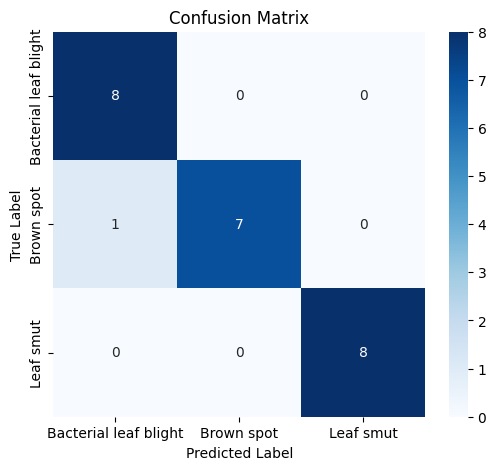

In [80]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes,
            yticklabels=classes)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()


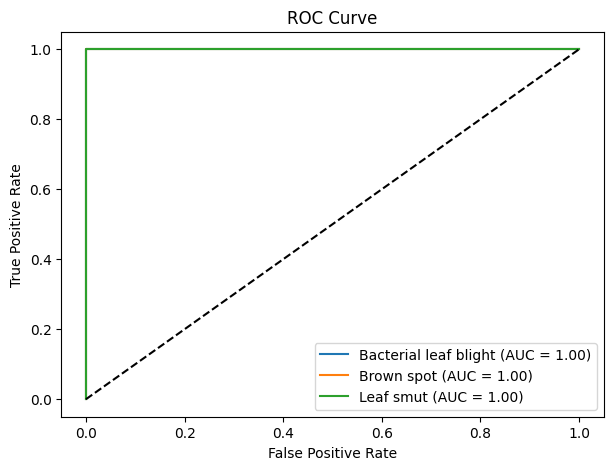

In [81]:
y_test_bin = label_binarize(y_test, classes=range(len(classes)))

plt.figure(figsize=(7,5))
for i in range(len(classes)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_probs[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{classes[i]} (AUC = {roc_auc:.2f})")

plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


In [82]:
#While Accuracy tells you how often the model is right overall, the Confusion Matrix tells you how it fails, and the ROC AUC tells you how confident it is in its classifications across different thresholds.

# Challenges Faced and Solutions

1. system-generated folders (such as .ipynb_checkpoints) may appear inside class directories.

solution:
Filtering files by valid image extensions ensures that only actual image files are included,
preventing runtime errors and improving data reliability.

2. Initial CNN models showed high training accuracy but poor validation and test performance, indicating overfitting.

Solution:
Regularization techniques such as Dropout and Early Stopping were used to control overfitting.

3. Data augmentation increased training data diversity but resulted in unstable validation performance for CNN models.

Solution:
Data augmentation was limited and used selectively. Instead of relying heavily on augmentation, transfer learning was chosen as a more effective approach for this dataset.

4. Due to limited data, validation and test sets contained few samples, increasing the risk of unreliable evaluation.

Solution:
Early stopping and careful train-validation splits were used to ensure stable evaluation, and final conclusions were based on test performance rather than training accuracy.

5. The dataset consisted of a small number of rice leaf images, which was insufficient for training deep learning models from scratch.

Solution:
Transfer learning using MobileNetV2 was applied. The pretrained ImageNet features helped the model learn meaningful patterns even with limited data, significantly improving accuracy.

# Future Scope and Next Steps

1. Expanding the Dataset

The current model was trained on a limited number of images. In the future, collecting a larger and more diverse dataset with varying lighting conditions, backgrounds, and disease stages can further improve model robustness and real-world applicability.

2. Fine-Tuning the Pretrained Model

While MobileNetV2 was used as a frozen feature extractor, future work can involve fine-tuning selected top layers of the pretrained model. This would allow the model to better adapt to rice leaf disease patterns and potentially achieve even higher accuracy.

3. Deployment as a Real-Time Application

The trained model can be deployed as a mobile or web-based application where farmers can upload images of rice leaves and receive instant disease predictions. This would make the system practical and accessible in real agricultural settings.

4. Multi-Disease and Multi-Crop Classification

Future versions of the system can be extended to detect multiple crop diseases across different plant species, transforming it into a generalized agricultural disease detection platform.

5. Integration with Advisory Systems

The classification model can be integrated with agricultural advisory systems to provide treatment recommendations, preventive measures, and disease management guidance along with predictions.

6. Use of Advanced Models and Ensembles

With more data available, advanced deep learning architectures or ensemble methods combining multiple pretrained models can be explored to further improve accuracy and reliability.
